# Integración numérica de ODEs

En este práctico introduciremos los métodos de **Euler** y de **RK4** (Runge-Kutta de orden 4) de integración numérica de Ecuaciones Diferenciales Ordinarias (ODEs).

## **Ejercicio 1)** Importando librerías

Importe las librerías `numpy` para operar con arrays, `scipy` para utilizar rutinas de algebra lineal y `matplotlib.pyplot` para graficar.

In [2]:
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

## **Ejercicio 2)** Integrador de **Euler**

### Ecuaciones Diferenciales Ordinarias (ODEs)

El comportamiento de un sistema dinámico se suele describir en términos de trayectorias. Una trayectoria es una función del tiempo

\begin{eqnarray}
x:\mathbb{R}\ni t\to x(t)\in X
\end{eqnarray}

en donde $x(t)\in X$ representa el estado que exhibe el sistema al tiempo $t$ y $X$ es un espacio vectorial.
Típicamente, $X=\mathbb{R}^n$.

Las trayectorias de un sistema dinámico suelen ser soluciones de una ecuación diferencial.
Nosotros, nos enfocaremos en sistemas dinámicos caracterizados por Ecuaciones Diferenciales Ordinarias (ODEs).

Decimos que una trayectoria $x:t\to x(t)$ es su solución de una ODE caracterizada por una función

\begin{eqnarray}
f: X,\mathbb{R} \ni x,t \to f(x,t) \in X
\end{eqnarray}

cuando

\begin{eqnarray}
x'(t) = f(x(t),t)
\end{eqnarray}

para todo tiempo $t$ perteneciente a algún intervalo de tiempo $ T\subseteq \mathbb{R}$. Aquí, $x'(t)$ es la derivada con respecto al tiempo $t$ de la función $x:t\to x(t)$ que representa la trayectoria.

En una ODE, una trayectoria particular $x$ queda unívocamente determinada por el valor de $x(t)$ en algún tiempo específico. Típicamente, se considera una *condición incial* $x(a)$, y nos interesa computar el valor de $x(t)$ para todo $t\in [a,b]$, i.e. conocer la trayectoria para todo tiempo entre un tiempo incial $a$ y un tiempo final $b$.

### Métodos de integración numérica de ODEs

Los métodos de integración de sistemas de Ecuaciones Diferenciales Ordinarias (ODEs) consisten, básicamente, de dos partes.

* Un método de extrapolación que permita aproximar **un paso de integración**, i.e. aproximar $x(t+h)$ a partir de conocer $t$, $x(t)$ y $f$ para valores de $h\in \mathbb{R}$ suficientementes pequeños.

* Un **integrador** de sucesivas aproximaciones $w_0$, $w_1$, ..., $w_k$ de los valores $x(a)$, $x(a+h)$, $x(a+2h)$, ..., $x(a+kh)=x(b)$ computadas secuencialmente a partir de un valor incial $w_0=x(a)$.

Existen varios métodos de aproximar un paso de integración.
En cambio, el integrador suele ser común a los diferentes métodos.

### Método de Euler

El método de Euler es, quizás, el más simple que existe.
Esencialmente, consiste en aproximar de $x(t+h)$ utilizando $f(x,t)$ para calcular la extrapolación lineal

\begin{eqnarray}
x(t+h)
&=&
x(t) + x'(t)h + x''(t)\frac{h^2}{2} + ...
\\
&\approx &
x(t) + x'(t)h
\\
&=&
x(t) + f(x(t),t)h
\end{eqnarray}

para un valor de $h$ que sea relativamente pequeño.

### Integrador

Si $t_0,t_1,...,t_n$ son valores equiespaciados en el intervalo de tiempo $[a,b]$, entonces $t_j=a+jh$ para $j\in \{0,1,2,...,k\}$ con $t_k=b$ y $h=(b-a)/k$.
Luego, utilizando el método $m$ proveido por el usuario, se computan sucesivamente las aproximaciones

\begin{eqnarray}
w_{j} &=& m(f,w_{j-1},t_{j-1},h)
\end{eqnarray}

de los valores $x(t+ih)$ para $j=1,...,n$, partiendo de la condición inicial $w_0=x(t_0)=x(a)$.

Por ejemplo, si el método proveido es el de Euler, las aproximaciones adoptan la forma

\begin{eqnarray}
w_{j} &=& w_{j-1} + f(w_{j-1},t_{j-1})h
\end{eqnarray}

**1)** Implemente una función de Python llamada `euler` que compute un paso de integración según el método de **Euler**.
Dicha función debe tomar como argumentos:

* La función $f:\mathbb{R}^n,\mathbb{R} \to \mathbb{R}^n$ que caracterize el lado derecho de la ODE.

* Un valor de $x \in \mathbb{R}^n$.

* Un valor de $t \in \mathbb{R}$.

* El paso de integración $h \in \mathbb{R}$.

* Un vector de parámetros $p \in \mathbb{R}^m$.

La función  `euler` debe retornar el lado derecho de la aproximación $x(t+h)\approx x(t) + f(x(t),t)h$.

**2)** Implemente una función de Python llamada `integrador_ode` que integre el cómputo de sucesivos pasos de integración.
Dicha función debe tomar como argumentos:

* Una función `m` que aproxime el paso de integración (ej. `euler`).

* La función $f:\mathbb{R}^n,\mathbb{R} \to \mathbb{R}^n$.

* La condición inicial $x_0=x(a)\in \mathbb{R}^n$.

* El tiempo inciial $a\in \mathbb{R}$.

* El tiempo final $b\in \mathbb{R}$.

* El número $k\in \mathbb{N}$ de pasos de integración.

* Un vector de parámetros $p \in \mathbb{R}^m$.

* Y, opcionalmente, una *función condicionante*
\begin{eqnarray}
c:\mathbb{R}^n,\mathbb{R},\mathbb{R}^m\ni x(t),t,p \to c(x(t),t,p)\in \mathbb{R}^n
\end{eqnarray}
que permita intervenir en el cómputo de la trayectoria cuando se desee.
Veremos más adelante para que sirve esta función condicionante.

In [3]:
# 2.1)
def euler(f,x,t,h,p):
    """
    Calcula un paso de integración de una EDO usando el método de Euler.

    Argumentos:
    f : función (x, t, p) -> array, que define el lado derecho de la EDO.
    x : array, el estado actual.
    t : float, el tiempo actual.
    h : float, el paso de integración.
    p : array, un vector de parámetros.

    Retorna:
        x_siguiente:  array, el siguiente paso de tiempo, x(t+h).
    """
    x_siguiente = x + h*f(x,t,p)
    return x_siguiente

In [4]:
#EJEMPLO DE USO
#EDO de decaimiento exponencial: dx/dt = -k*x
def decaimiento_exponencial(x,t,p):
    k = p[0]
    return -k*x

x0 = np.array([100.0])
t0 = 0.0
h_step = 0.1
parametros = np.array([0.5])

x1 = euler(decaimiento_exponencial,x0,t0,h_step,parametros)
print(f"Estados inicial x(t=0) : {x0}")
print(f"Estados final x(t=h) : {x1}")

Estados inicial x(t=0) : [100.]
Estados final x(t=h) : [95.]


In [6]:
# 2.2)
def euler(f, x, t, h, p):
  return x + h *f(x, t, p)

def integrador_ode(m,f,x0,t0,tf,npasos,p):
    """
    Integra una EDO desde un tiempo inicial a uno final usando un método dado.

    Argumentos de entrada:

        m  : str, el metodo a usar ('e para Euler)
        f  : funcion (x, t, p), lado derecho de la EDO.
        x0 : array, condición inicial x(t0).
        t0 : float, tiempo inicial.
        tf : float, tiempo final.
        npasos : int, número de pasos de integración.
        p  : array, vector de parámetros.

    Retorna:
      (array, array), vector de tiempos y matriz de estados.

    """
    h = (tf - t0) / npasos

    t_puntos = np.zeros(npasos + 1)
    x_puntos = np.zeros((npasos + 1, len(x0)))

    t_puntos[0] = t0
    x_puntos[0] = x0
    if m == 'e':
      for i in range(npasos):
        x_actual = x_puntos[i]
        t_actual = t_puntos[i]

        x_siguiente = euler(f, x_actual, t_actual, h, p)


        x_puntos[i+1] = x_siguiente
        t_puntos[i+1] = t_actual + h
    else:
      raise ValueError("Método no soportado. Use 'e' para Euler.")

    return t_puntos, x_puntos


In [7]:
def decaimiento_exponencial(x, t, p):
  k = p[0]
  return -k * x

x_inicial = np.array([100.0])
tiempo_inicial = 0.0
tiempo_final = 10.0
n_pasos = 50
parametros_k = np.array([0.5])

tiempos, solucion = integrador_ode(
      'e',
      decaimiento_exponencial,
      x_inicial,
      tiempo_inicial,
      tiempo_final,
      n_pasos,
      parametros_k
)

Tiempo (t) | Solución (x)
-------------------------
0.00          | 100.0000
0.20          | 90.0000
0.40          | 81.0000
0.60          | 72.9000
0.80          | 65.6100
1.00          | 59.0490
1.20          | 53.1441
1.40          | 47.8297
1.60          | 43.0467
1.80          | 38.7420
2.00          | 34.8678
2.20          | 31.3811
2.40          | 28.2430
2.60          | 25.4187
2.80          | 22.8768
3.00          | 20.5891
3.20          | 18.5302
3.40          | 16.6772
3.60          | 15.0095
3.80          | 13.5085
4.00          | 12.1577
4.20          | 10.9419
4.40          | 9.8477
4.60          | 8.8629
4.80          | 7.9766
5.00          | 7.1790
5.20          | 6.4611
5.40          | 5.8150
5.60          | 5.2335
5.80          | 4.7101
6.00          | 4.2391
6.20          | 3.8152
6.40          | 3.4337
6.60          | 3.0903
6.80          | 2.7813
7.00          | 2.5032
7.20          | 2.2528
7.40          | 2.0276
7.60          | 1.8248
7.80          | 1.6423
8.00 

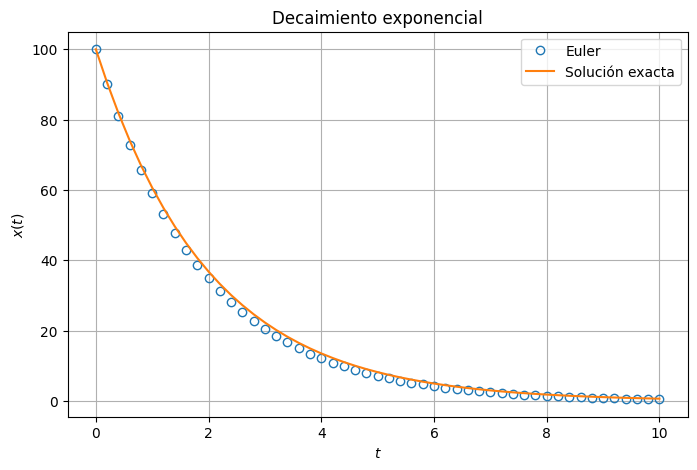

In [9]:
# --- TABLA DE RESULTADOS ---
print("Tiempo (t) | Solución (x)")
print("-------------------------")

for i in range(0, n_pasos + 1):
  print(f"{tiempos[i]:.2f}          | {solucion[i][0]:.4f}")


# --- GRÁFICO ---
# Solución exacta
k = parametros_k[0]
x_exacta = x_inicial[0] * np.exp(-k * tiempos)
plt.figure(figsize=(8, 5))


# Solución numérica de Euler: círculos huecos
plt.plot(
tiempos,
solucion[:, 0],
'o',
markerfacecolor='none',
label='Euler'
)


# Solución exacta: línea continua
plt.plot(
tiempos,
x_exacta,
'-',
label='Solución exacta'
)

plt.xlabel(r'$t$')
plt.ylabel(r'$x(t)$')
plt.title('Decaimiento exponencial')
plt.grid(True)
plt.legend()
plt.show()

## **Ejercicio 3)** Crecimiento exponencial

Considere la ODE

\begin{eqnarray}
x'(t)
&=&
qx(t)
\end{eqnarray}

donde $q$ es una constante positiva.

**1)** Utilice el integrador ODE implementado en el ejercicio 2) para integrar la ODE arriba definida, a partir de la condición inicial $x(t=0)=1$ hasta el tiempo $t=3$, y para $q=1$. Utilice el paso de integración $h=0.1$.

**2)** Grafique la solución numérica computada en el inciso anterior. Incluya en el gráfico la solución exacta que se deriva a continuación

\begin{eqnarray}
x'(t)
&=&
qx(t)
\\
\frac{dx}{dt}
&=&
qx
\\
\frac{dx}{x}
&=&
qdt
\\
\int_{x(0)}^{x(\tau)}
\frac{dx}{x}
&=&
q
\int_0^{\tau} dt
\\
\ln(x(\tau))-\ln(x(0))
&=&
q\tau
\\
\ln(x(t))
&=&
qt
+
\ln(x(0))
\\
x(t)
&=&
e^{
qt
+
\ln(x(0))
}
\\
x(t)
&=&
e^{\ln(x(0))}
e^{qt}
\\
x(t)
&=&
x(0)
e^{qt}
\end{eqnarray}

**3)** Repita para $h=0.01$.

In [13]:
#3.1)
#definicion de f
def f(x, t, p):
    q = p[0]
    return q * x

In [15]:
#Parametros

q = 1.0
p = [q]
x0 = np.array([1.0])  # Condición inicial como vector 1D
t0 = 0.0
tf = 3.0

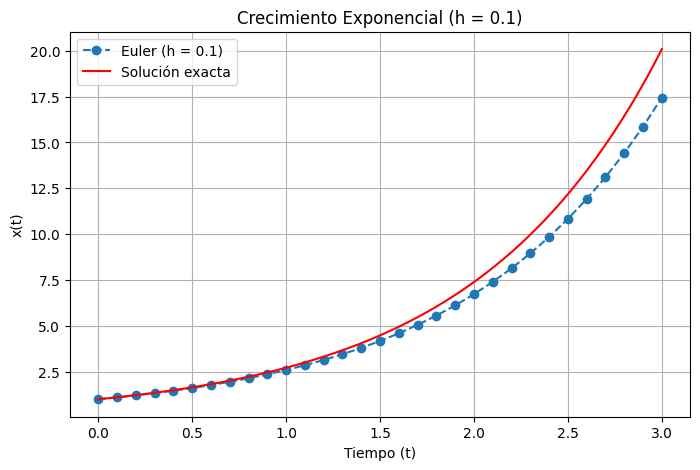

In [16]:
# 1 y 2) Para h = 0.1

h1 = 0.1
npasos1 = int((tf - t0) / h1)
t_num1, x_num1 = integrador_ode('e', f, x0, t0, tf, npasos1, p)

# Solución exacta
t_exacta = np.linspace(t0, tf, 200)
x_exacta = x0[0] * np.exp(q * t_exacta)

# Gráfico h = 0.1
plt.figure(figsize=(8, 5))
plt.plot(t_num1, x_num1, 'o--', label=f'Euler (h = {h1})')
plt.plot(t_exacta, x_exacta, 'r-', label='Solución exacta')
plt.title('Crecimiento Exponencial (h = 0.1)')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

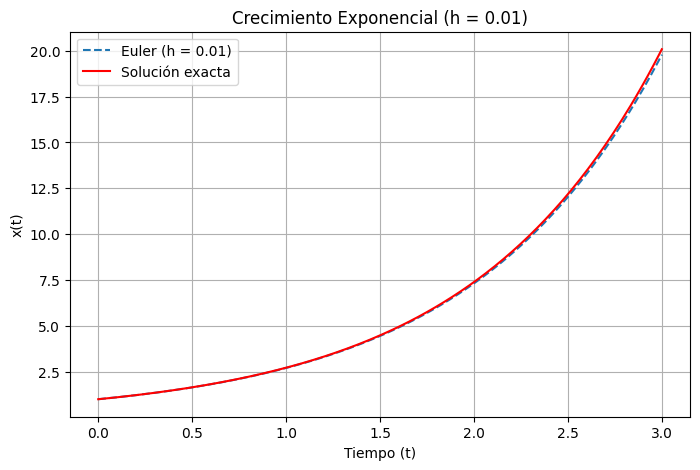

In [17]:
# 3) Para h = 0.01
h2 = 0.01
npasos2 = int((tf - t0) / h2)
t_num2, x_num2 = integrador_ode('e', f, x0, t0, tf, npasos2, p)

# Gráfico h = 0.01
plt.figure(figsize=(8, 5))
plt.plot(t_num2, x_num2, '--', label=f'Euler (h = {h2})')
plt.plot(t_exacta, x_exacta, 'r-', label='Solución exacta')
plt.title('Crecimiento Exponencial (h = 0.01)')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

## **Ejercicio 4)** Convergencia exponencial

Considere la ODE

\begin{eqnarray}
x'(t)
&=&
-qx(t)+r
\end{eqnarray}

donde $q$ es una constante positiva y $r$ es una constante arbitraria.

**1)** Use el integrador ODE con el método de Euler para encontrar una aproximación numérica de la ODE arriba especificada.
Considere la condición inicial $x(0)=3$ e integre hasta $t=3$.
Utilice el paso de integración $h=0.1$ y los valores de los parámetros $q=2$ y $r=3$.

**2)** Grafique la trayectoria computada en el inciso anterior y, con el fin de comparar, grafique simultaneamente la correspondiente solución analítica derivada a continuación

\begin{eqnarray}
\frac{dx}{dt}
&=&
-qx+r
\\
-\frac{1}{q}\frac{du}{dt}
&=&
u,
\;\;\;\;
\;\;\;\;
\;\;\;\;
u=-qx+r
\\
\frac{du}{dt}
&=&
-qu
\\
u(t)
&=&
u(0)e^{-qt}
\\
-qx(t)+r
&=&
(-qx(0)+r)e^{-qt}
\\
x(t)
&=&
(x(0)-r/q)e^{-qt}+r/q
\end{eqnarray}

**3)** Repita para $h=0.01$.

**4)** Repita para $x(0)=1$.

In [20]:
# 4.1) Definición del lado derecho de la ODE: x'(t) = -q*x + r
def f(x, t, p):
    q = p[0]
    r = p[1]
    return -q * x + r

In [21]:
# Solución analítica derivada en la imagen
def sol_analitica(t, x0, q, r):
    return (x0 - r/q) * np.exp(-q * t) + (r / q)

# Parámetros del problema
q = 2.0
r = 3.0
p = [q, r]
t0 = 0.0
tf = 3.0

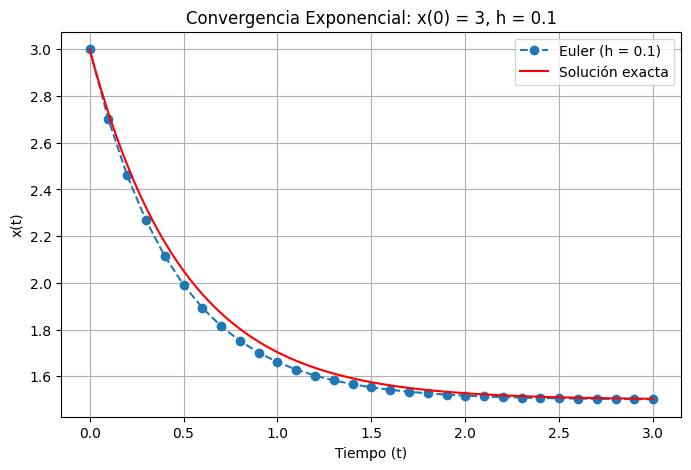

In [22]:
# Puntos 1 y 2: x(0) = 3 con h = 0.1

x0_a = np.array([3.0])
h1 = 0.1
npasos1 = int((tf - t0) / h1)

t_num1, x_num1 = integrador_ode('e', f, x0_a, t0, tf, npasos1, p)
f
t_exacta = np.linspace(t0, tf, 200)
x_exacta1 = sol_analitica(t_exacta, x0_a[0], q, r)

plt.figure(figsize=(8, 5))
plt.plot(t_num1, x_num1, 'o--', label=f'Euler (h = {h1})')
plt.plot(t_exacta, x_exacta1, 'r-', label='Solución exacta')
plt.title('Convergencia Exponencial: x(0) = 3, h = 0.1')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

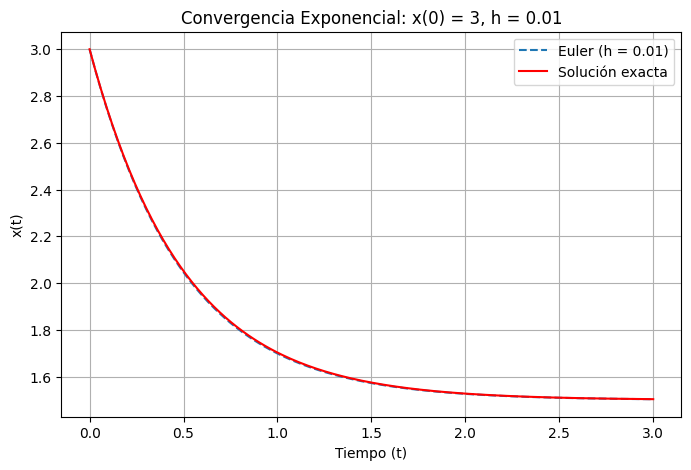

In [23]:
# Punto 3: Repetir para h = 0.01 con x(0) = 3

h2 = 0.01
npasos2 = int((tf - t0) / h2)

t_num2, x_num2 = integrador_ode('e', f, x0_a, t0, tf, npasos2, p)

plt.figure(figsize=(8, 5))
plt.plot(t_num2, x_num2, '--', label=f'Euler (h = {h2})')
plt.plot(t_exacta, x_exacta1, 'r-', label='Solución exacta')
plt.title('Convergencia Exponencial: x(0) = 3, h = 0.01')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

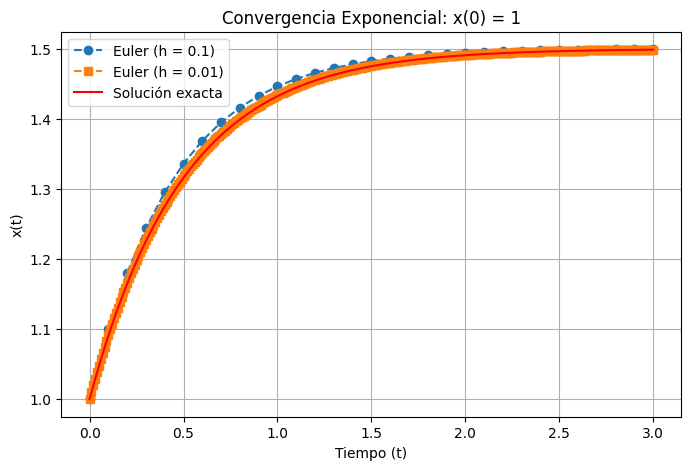

In [24]:
# Punto 4: Repetir para x(0) = 1 (con h = 0.1 y h = 0.01)

x0_b = np.array([1.0])
x_exacta2 = sol_analitica(t_exacta, x0_b[0], q, r)

t_num_b1, x_num_b1 = integrador_ode('e', f, x0_b, t0, tf, npasos1, p)
t_num_b2, x_num_b2 = integrador_ode('e', f, x0_b, t0, tf, npasos2, p)

plt.figure(figsize=(8, 5))
plt.plot(t_num_b1, x_num_b1, 'o--', label=f'Euler (h = {h1})')
plt.plot(t_num_b2, x_num_b2, 's--', label=f'Euler (h = {h2})')
plt.plot(t_exacta, x_exacta2, 'r-', label='Solución exacta')
plt.title('Convergencia Exponencial: x(0) = 1')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

## **Ejercicio 5)** Ecuación Logística

Considere la ODE

\begin{eqnarray}
x'(t)
&=&
rx(t)(1-x(t)/K)
\end{eqnarray}

**1)** Integre numéricamente la anterior ODE utilizando el método de Euler, la condición inicial $x(0)=0.1$, hasta $t=5$, utilizando un paso de integración $h=0.1$, una tasa de reproducción $r=1$ y una capacidad de carga $K=1$.

**2)** Grafique la solución computada en el inciso anterior, comparandola con la solución analítica que se deriva a continuación

\begin{eqnarray}
\frac{dx}{dt}
&=&
rx(1-x/K)
\\
\frac{dx}{x(1-x/K)}
&=&
rdt
\\
\int_{x(0)}^{x(t)}\frac{dx}{x(1-x/K)}
&=&
rt
\\
\int_{x(0)}^{x(t)}dx\,\frac{1}{x}+\frac{1}{K-x}
&=&
rt
\\
\ln(x(t))-\ln(x(0))
-
\ln(K-x(t))
+
\ln(K-x(0))
&=&
rt
\\
\ln\frac{x(t)}{K-x(t)}
&=&
rt
+
\ln\frac{x(0)}{K-x(0)}
\\
\frac{x(t)}{K-x(t)}
&=&
f(t)
=
\frac{x(0)}{K-x(0)}e^{rt}
\\
x(t)
&=&
(K-x(t))f(t)
\\
x(t)(1+f(t))
&=&
Kf(t)
\\
x(t)
&=&
K\frac{f(t)}{1+f(t)}
=
K\frac{1}{1+\frac{1}{f(t)}}
\\
x(t)
&=&
K\left(1+\frac{K-x(0)}{x(0)}e^{-rt}\right)^{-1}
\end{eqnarray}

**3)** Repita para $x(0)=1.5$.

In [25]:
# Definición de la ODE logística
def ode_logistica(x, t, p):
    r, K = p[0], p[1]
    return r * x * (1.0 - x / K)

In [26]:
# Solución analítica exacta deducida en la imagen
def sol_analitica_logistica(t, x0, r, K):
    return K / (1.0 + ((K - x0) / x0) * np.exp(-r * t))

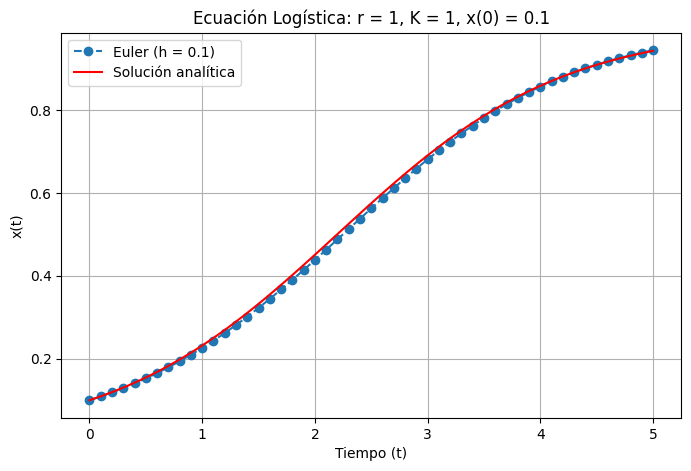

In [29]:
# Parámetros del problema
r = 1.0           # Tasa de reproducción
K = 1.0           # Capacidad de carga
p = [r, K]

x0 = np.array([0.1])  # Condición inicial x(0) = 0.1
t0 = 0.0              # Tiempo inicial
tf = 5.0              # Tiempo final

# Paso de integración h = 0.1
h = 0.1
npasos = int((tf - t0) / h)  # 50 pasos

# 1) Integración numérica con método de Euler
t_num, x_num = integrador_ode('e', ode_logistica, x0, t0, tf, npasos, p)

# Solución analítica para comparar
t_exacta = np.linspace(t0, tf, 200)
x_exacta = sol_analitica_logistica(t_exacta, x0[0], r, K)

# 2) Gráfico comparativo
plt.figure(figsize=(8, 5))
plt.plot(t_num, x_num, 'o--', label=f'Euler (h = {h})')
plt.plot(t_exacta, x_exacta, 'r-', label='Solución analítica')
plt.title('Ecuación Logística: r = 1, K = 1, x(0) = 0.1')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

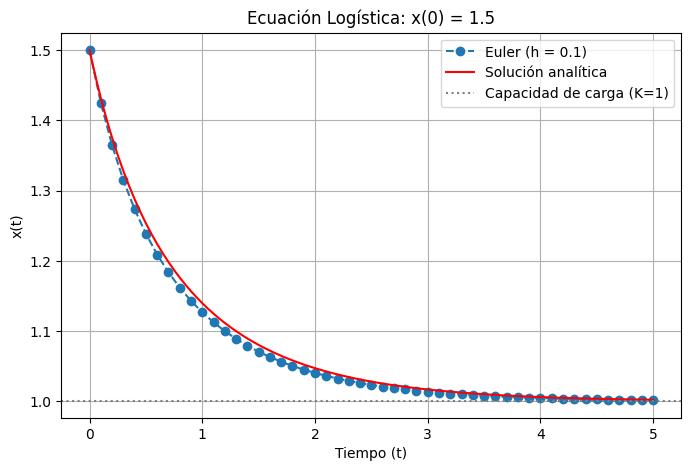

In [30]:
# Nueva condición inicial x(0) = 1.5
x0_3 = np.array([1.5])  # Mayor a la capacidad de carga K = 1

# Integración numérica
t_num3, x_num3 = integrador_ode('e', ode_logistica, x0_3, t0, tf, npasos, p)

# Solución analítica
t_exacta = np.linspace(t0, tf, 200)
x_exacta3 = sol_analitica_logistica(t_exacta, x0_3[0], r, K)

# Gráfico
plt.figure(figsize=(8, 5))
plt.plot(t_num3, x_num3, 'o--', label=f'Euler (h = {h})')
plt.plot(t_exacta, x_exacta3, 'r-', label='Solución analítica')
plt.axhline(K, color='gray', linestyle=':', label='Capacidad de carga (K=1)')
plt.title('Ecuación Logística: x(0) = 1.5')
plt.xlabel('Tiempo (t)')
plt.ylabel('x(t)')
plt.grid(True)
plt.legend()
plt.show()

## **Ejercicio 6)** Oscilador armónico

### Redución del orden de una ODE

Comunmente, una Ordinary Differential Equation (ODE) de orden $n$ tiene la siguiente forma

\begin{eqnarray}
y^{(n)}(t)
&=&
f(y(t),y'(t),y''(t),...,y^{(n-1)}(t),t)
\;\;\;\; (1)
\end{eqnarray}

donde $y^{(i)}$ denota la $i$-ésima derivada de $y$ respecto a $t$.
Dicha ODE es de dimensión $d$ si $x:\mathbb{R}\ni t\to y(t)\in \mathbb{R}^d$.

La ODE de la ecuación $(1)$ siempre puede reducirse a una ODE de primer orden y dimensión $nd$ utilizando la siguiente transformación

\begin{eqnarray}
x_1:t\to x_1(t) &:=& y(t) \\
x_2:t\to x_2(t) &:=& y'(t) = x_1'(t) \\
x_3:t\to x_3(t) &:=& y''(t) = x_2'(t) \\
&...& \\
x_n:t\to x_n(t) &:=& y^{(n-1)}(t) = x_{n-1}'(t) \\
x_n':t\to x_n'(t) &=& y^{(n)}(t)
\end{eqnarray}

que vale para todo $t\in [a,b]$. De esta manera, la ecuación $(1)$ adopta la forma

\begin{eqnarray}
x_{1}'(t) &=& x_2(t) \\
x_{2}'(t) &=& x_3(t) \\
&...& \\
x_{n-1}'(t) &=& x_n(t) \\
x_n'(t) &=& f(x_1(t),x_2(t),x_3(t),...,x_{n}(t),t)
\end{eqnarray}

lo cual constituye una ODE de primer orden y dimensión $nd$ como se mencionó.

### El oscilador armónico

El oscilador armónico viene descripto por la siguiente ODE

\begin{eqnarray}
y''(t) &=& -\alpha y(t)
\end{eqnarray}

Esta es una ODE de segundo orden, ya que aparece la derivada segunda de la función $x:t\to x(t)$.
La convertimos a una de primer orden definiendo $x_1=y$ y $x_2=y'$, obteniéndose

\begin{eqnarray}
x_1'(t) &=& x_2(t) \\
x_2'(t) &=& -\alpha x_1(t)
\end{eqnarray}

**1)** Utilice lo implementado en el ejecicio 2) para resolver en el intervalo de tiempo $[a,b]=[0,10]$ la ODE del oscilador armónico sujeto a las siguientes condiciones iniciales

\begin{eqnarray}
x_1(a) &=& y(a) = 1 \\
x_2(a) &=& y'(a) = 0
\end{eqnarray}

para $\alpha=3$ y usando un paso de integración $h=0.1$.

**2)** Grafique $x_1(t)$ vs $t$ y $x_2(t)$ vs $t$. No olvide agregar leyendas a los ejes y las curvas.
Use `np.scatter()` en vez de `np.plot()` para graficar usando puntos en vez de curvas.

**3)** Grafique $x_2(t)$ vs $x_1(t)$ paramétricamente en función de $t$.

In [31]:
def oscilador_armonico(x, t, p):
  alpha = p[0]
  x1 = x[0]
  x2 = x[1]
  return np.array([x2, -alpha * x1])

In [33]:
# Condiciones y parámetros del Ejercicio 6
x_inicial = np.array([1.0, 0.0])
tiempo_inicial = 0.0
tiempo_final = 10.0
h_step = 0.1
n_pasos = int((tiempo_final - tiempo_inicial) / h_step) #100
parametros_alpha = np.array([3.0])

# Integración
tiempos, solucion = integrador_ode(
    'e', oscilador_armonico, x_inicial,
    tiempo_inicial, tiempo_final, n_pasos, parametros_alpha )


x1 = solucion[:, 0]
x2 = solucion[:, 1]

In [35]:
# Primeros 10 pasos (más la condición inicial)
print(" n | t_n | x1_n | x2_n")
print("--------------------------")

for n in range(11):
  print(f"{n:2d} | {tiempos[n]:.1f} | {x1[n]: .10f} | {x2[n]: .10f}")

 n | t_n | x1_n | x2_n
--------------------------
 0 | 0.0 |  1.0000000000 |  0.0000000000
 1 | 0.1 |  1.0000000000 | -0.3000000000
 2 | 0.2 |  0.9700000000 | -0.6000000000
 3 | 0.3 |  0.9100000000 | -0.8910000000
 4 | 0.4 |  0.8209000000 | -1.1640000000
 5 | 0.5 |  0.7045000000 | -1.4102700000
 6 | 0.6 |  0.5634730000 | -1.6216200000
 7 | 0.7 |  0.4013110000 | -1.7906619000
 8 | 0.8 |  0.2222448100 | -1.9110552000
 9 | 0.9 |  0.0311392900 | -1.9777286430
10 | 1.0 | -0.1666335743 | -1.9870704300


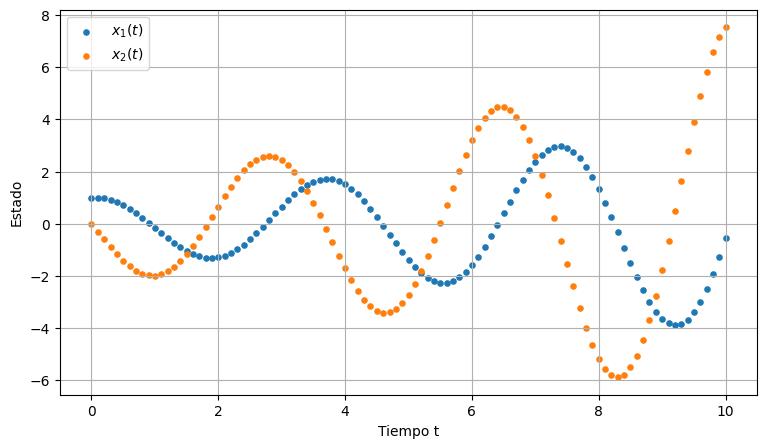

In [36]:
# x1(t) y x2(t) vs t, usando puntos
plt.figure(figsize=(9, 5))
plt.scatter(tiempos, x1, s=14, label=r'$x_1(t)$')
plt.scatter(tiempos, x2, s=14, label=r'$x_2(t)$')
plt.xlabel('Tiempo t')
plt.ylabel('Estado')
plt.legend()
plt.grid(True)
plt.show()

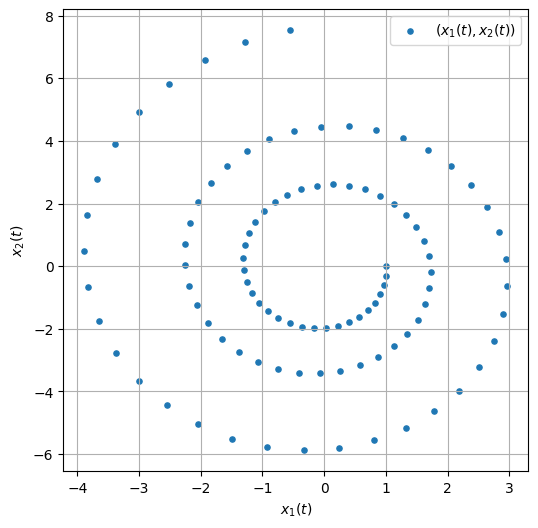

In [37]:
# Diagrama de fase: x2(t) frente a x1(t)
plt.figure(figsize=(6, 6))
plt.scatter(x1, x2, s=14, label=r'$(x_1(t),x_2(t))$')
plt.xlabel(r'$x_1(t)$')
plt.ylabel(r'$x_2(t)$')
plt.legend()
plt.grid(True)
plt.show()

## **Ejercicio 7)** Integrador de **RK4**

El método de Runge-Kutta de orden 4 utiliza la teoría de diferencias finitas para calcular la siguiente aproximación de orden 4to de un paso de integración.
A saber
\begin{eqnarray}
x(t+h)
&=&
x(t)
+
\frac{h}{6}
(k_1+2k_2+2k_3+k_4)
+
\mathcal{O}(h^5)
\end{eqnarray}

donde

\begin{eqnarray}
k_1 &=& f(x,t) \\
k_2 &=& f(x+hk_1/2,t+h/2) \\
k_3 &=& f(x+hk_2/2,t+h/2) \\
k_4 &=& f(x+hk_3,t+h)
\end{eqnarray}

**1)** Implemente el método de RK4.

**2)** Repita el ejercicio **6)** pero usando **RK4** en vez de **Euler**.

**3)** Nota alguna diferencia al comparar la solución obtenida con Euler y la solución obtenida con RK4?

In [41]:
def euler(f, x, t, h, p):
  return x + h * f(x, t, p)

In [42]:
def rk4(f, x, t, h, p):
    """Computa un paso de integración con Runge-Kutta de orden 4."""

    k1 = f(x, t, p)
    k2 = f(x + 0.5 * h * k1, t + 0.5 * h, p)
    k3 = f(x + 0.5 * h * k2, t + 0.5 * h, p)
    k4 = f(x + h * k3, t + h, p)
    x_siguiente = x + (h / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

    return x_siguiente

In [43]:
def integrador_ode(m, f, x0, t0, tf, npasos, p):

  h = (tf - t0) / npasos

  t_puntos = np.zeros(npasos + 1)
  x_puntos = np.zeros((npasos + 1, len(x0)))
  t_puntos[0] = t0
  x_puntos[0] = x0

  for i in range(npasos):
    x_actual = x_puntos[i]
    t_actual = t_puntos[i]

    if m == 'e':
      x_siguiente = euler(f, x_actual, t_actual, h, p)
    elif m == 'rk4':
      x_siguiente = rk4(f, x_actual, t_actual, h, p)
    else:
      raise ValueError("Método no soportado. Use 'e' o 'rk4'.")
    x_puntos[i+1] = x_siguiente
    t_puntos[i+1] = t_actual + h

  return t_puntos, x_puntos

In [ ]:
#Definimos el aocilador armonico
def oscilador_armonico(x, t, p):
  alpha = p[0]
  x1 = x[0]
  x2 = x[1]
  return np.array([x2, -alpha * x1])

In [44]:
x_inicial = np.array([1.0, 0.0])
tiempo_inicial = 0.0
tiempo_final = 10.0
h_step = 0.1
n_pasos = int((tiempo_final - tiempo_inicial) / h_step)
parametros_alpha = np.array([3.0])


In [46]:
# Integración con RK4
tiempos_rk4, solucion_rk4 = integrador_ode(
'rk4', oscilador_armonico, x_inicial,
tiempo_inicial, tiempo_final, n_pasos, parametros_alpha
)

x1_rk4 = solucion_rk4[:, 0]
x2_rk4 = solucion_rk4[:, 1]

# Solución exacta para comparar
alpha = parametros_alpha[0]
omega = np.sqrt(alpha)
tiempos_exactos = np.linspace(tiempo_inicial, tiempo_final, 1000)
x1_exacta = np.cos(omega * tiempos_exactos)
x2_exacta = -omega * np.sin(omega * tiempos_exactos)

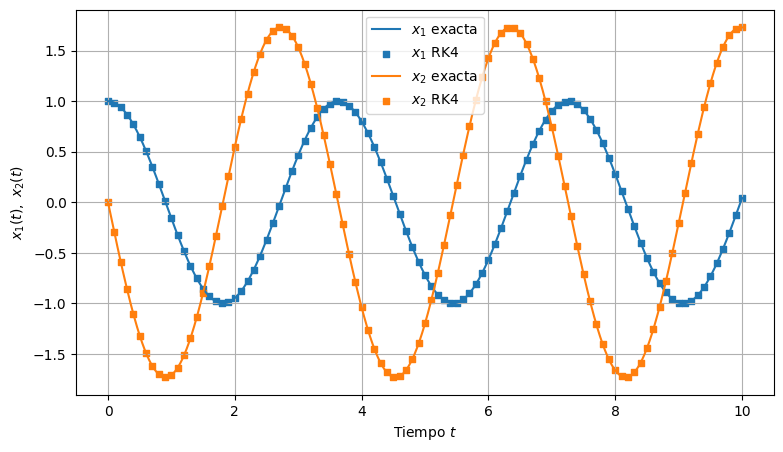

In [47]:
# x1(t) y x2(t) frente a t: solución exacta y RK4
plt.figure(figsize=(9, 5))
plt.plot(tiempos_exactos, x1_exacta, color='C0', label=r'$x_1$ exacta')
plt.scatter(tiempos_rk4, x1_rk4, s=14, marker='s', color='C0', label=r'$x_1$ RK4')
plt.plot(tiempos_exactos, x2_exacta, color='C1', label=r'$x_2$ exacta')
plt.scatter(tiempos_rk4, x2_rk4, s=14, marker='s', color='C1', label=r'$x_2$ RK4')
plt.xlabel(r'Tiempo $t$')
plt.ylabel(r'$x_1(t),\ x_2(t)$')
plt.legend()
plt.grid(True)
plt.show()

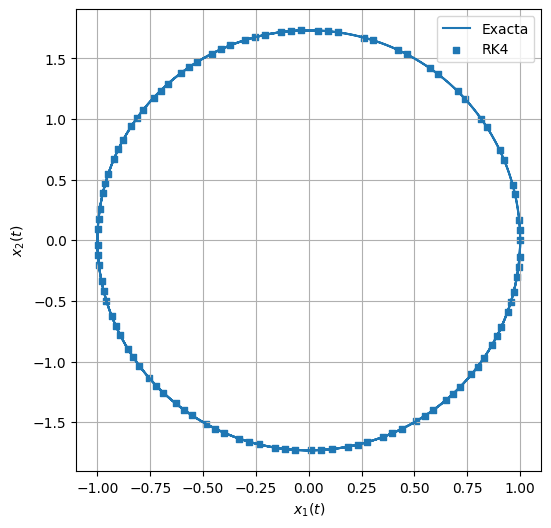

In [48]:
# Diagrama de fases: x2(t) frente a x1(t)
plt.figure(figsize=(6, 6))
plt.plot(x1_exacta, x2_exacta, color='C0', label='Exacta')
plt.scatter(x1_rk4, x2_rk4, s=14, marker='s', color='C0', label='RK4')
plt.xlabel(r'$x_1(t)$')
plt.ylabel(r'$x_2(t)$')
plt.legend()
plt.grid(True)
plt.show()

### 7.3)
Observamos que con el método de Euler (ej. **7)**) la curva forma una espiral debido al error numérico que se acumula a medida que avanza el tiempo $t
. Por otr lado, vemos que con el método RK4, la curva forma un elipsoide, que es lo correcto.

## **Ejercicio 8)** Creando una "libreria" de integradores ODE

**1)** Exporte el actual notebook `redes-neuronales-2022-practico-4.ipynb` a `ode.py`.

**2)** Con su editor de texto favorito, elimine todo lo que sobra de `ode.py`. Deje, solamente, el código que:

* importa `numpy`.

* define la funcion `euler`.

* define la funcion `rk4`.

* define la funcion `integrador_ode`.

**3)** En google colab, suba el archivo `ode.py` anteriormente creado.

**4)** Importe la "libreria" `ode` escribiendo

    import ode

**5)** Pruebe la libreria `ode` escribiendo

    t,x = ode.integrador_ode(ode.rk4,f,xa,a,b,k,p)

In [54]:
import ode

In [55]:
# Definir una ODE de prueba (ejemplo: x' = -x)
def f_prueba(x, t, p):
    return -x

# Parámetros de prueba
xa = np.array([1.0])  # x0
a = 0.0               # t0
b = 2.0               # tf
k = 20                # npasos
p = []                # parámetros vacíos

# 5) Probar la librería ode
t, x = ode.integrador_ode(ode.rk4, f_prueba, xa, a, b, k, p)

print("Integración completada exitosamente!")
print("Tiempos:", t[:5])
print("Estados x(t):", x[:5].ravel())

Integración completada exitosamente!
Tiempos: [0.  0.1 0.2 0.3 0.4]
Estados x(t): [1.         0.9048375  0.8187309  0.74081842 0.67032029]
